# Adding Problem: Long-Term Dependency Learning Task

This notebook implements the adding problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies. The task requires computing the sum of two specific numbers from a sequence of random numbers.

## Task Description

- Input: 2-dimensional vector at each time step
  - First dimension: Random number in [0, 1]
  - Second dimension: Boolean indicator (1 for numbers to add, 0 otherwise)
- Sequence length: 20 time steps
- Objective: Sum the two numbers where the boolean indicator is 1
- This tests the network's ability to remember and combine information from different time steps

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [16]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [17]:
class ParityDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        vector = 2 * torch.randint(0, 2, (self.num_samples, 1, self.seq_len)) - 1
        zero_padding = torch.zeros((self.num_samples, self.seq_len-1, self.seq_len))
        self.data = torch.cat((vector, zero_padding), dim=1)
        # self.data = vector.float()
        negatives = (vector == -1).to(torch.long)
        cumsum = torch.cumsum(negatives, dim=-1)
        self.target = (cumsum % 2 != 0).to(torch.long).squeeze(-2)

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]

# Create datasets
train_dataset = ParityDataset(seq_len=20, num_samples=50000)
test_dataset = ParityDataset(seq_len=20, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input}")
print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([[ 1.,  1., -1.,  1., -1., -1., -1., -1.,  1.,  1., -1., -1., -1., -1.,
         -1.,  1., -1., -1., -1., -1.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,

## 3. Visualize Sample Data


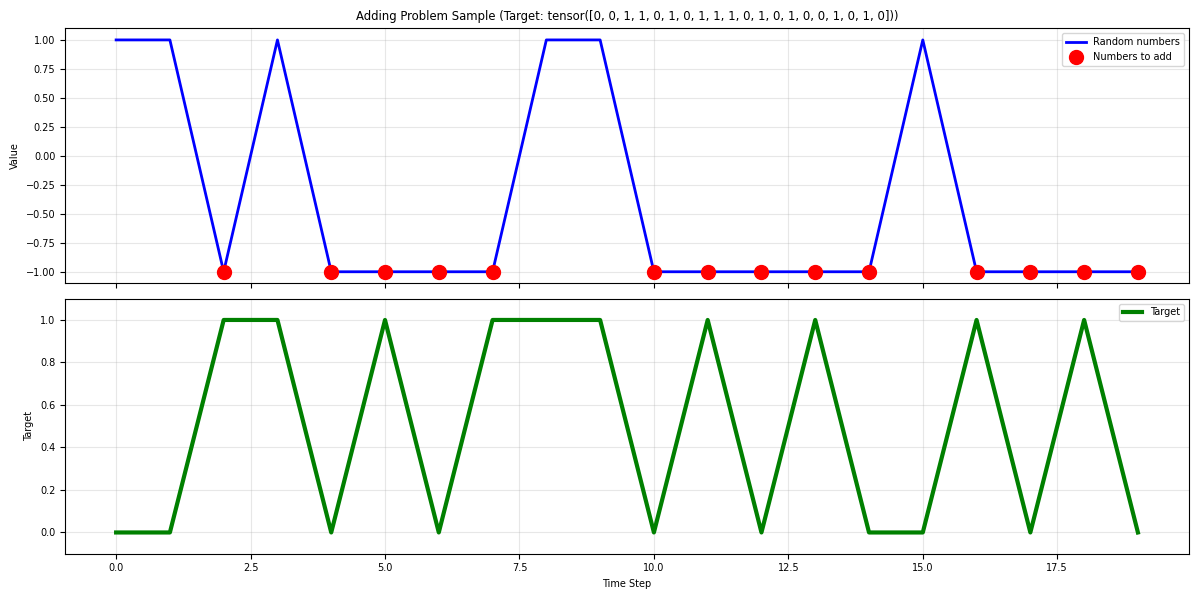

Target: tensor([0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0])


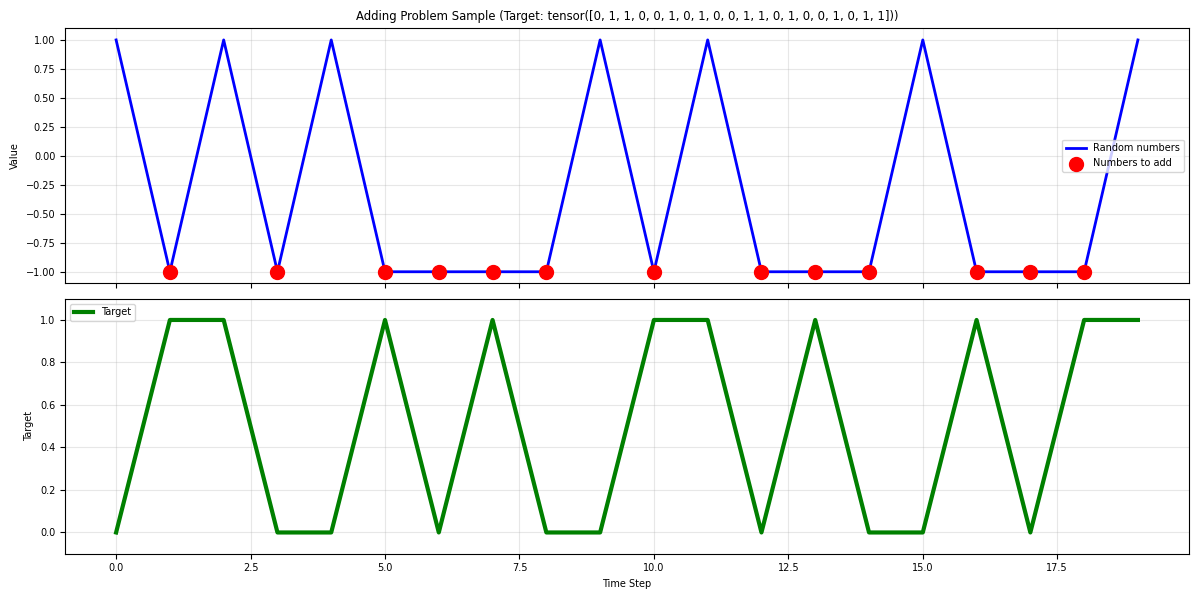

Target: tensor([0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1])


In [18]:
def visualize_adding_problem_sample(dataset, idx=0):
    """
    Visualize a sample from the adding problem dataset.
    """
    input_seq, target = dataset[idx]
    input_seq = input_seq[0]
    seq_len = input_seq.shape[0]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    # Plot the random numbers
    ax1.plot(range(seq_len), input_seq, 'b-', linewidth=2, label='Random numbers')
    # Highlight the numbers to be added
    marked_indices = np.where(input_seq == -1)[0]
    ax1.scatter(marked_indices, input_seq[marked_indices],
               color='red', s=100, zorder=5, label='Numbers to add')
    ax1.set_ylabel('Value')
    ax1.set_title(f'Adding Problem Sample (Target: {target})')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot the indicators
    ax2.plot(range(seq_len), target, 'g-', linewidth=3, label='Target')
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('Target')
    ax2.set_ylim(-0.1, 1.1)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


    print(f"Target: {target}")

# Visualize a few samples
visualize_adding_problem_sample(train_dataset, 0)
visualize_adding_problem_sample(train_dataset, 1)

## 4. Training Functions


In [19]:
def train_model(model, train_loader, test_loader, epochs=100, lr=0.001):
    """
    Train a model on the adding problem.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    # criterion = nn.L1Loss()

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)
    test_accs = torch.zeros(epochs // test_every)

    model.train()

    for epoch in range(epochs):
        # print(epoch)
        # Training
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        batch_inputs, batch_targets = next(iter(train_loader))
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_inputs:', batch_inputs.shape)
        batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
        B, T = batch_targets.shape

        # print('batch_targets:', batch_targets.shape)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)
        # print('outputs:', outputs.shape)

        predictions = outputs[-1].reshape(B, T, 2).flatten(0,1)
        target = batch_targets.flatten(0,1)
        decoding_loss = criterion(predictions, target)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_accuracy = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
                    B, T = batch_targets.shape

                    outputs, _, hidden = model(batch_inputs)
                    # print('outputs:', outputs.shape)
                    predictions = outputs[-1].reshape(B, T, 2).flatten(0,1)
                    target = batch_targets.flatten(0,1)

                    loss = criterion(predictions, target)
                    predict_label = torch.argmax(predictions, dim=-1)
                    accuracy = (predict_label == target).float().mean().item()
                    total_test_loss += loss.item()
                    total_test_accuracy += accuracy
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_accuracy = total_test_accuracy / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss
            test_accs[epoch // test_every] = avg_test_accuracy

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_accuracy:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)
            B, T = batch_targets.shape

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1].reshape(B, T, 2).flatten(0,1)
            target = batch_targets.flatten(0,1)

            loss = criterion(preds, target)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    # print('type:', type(predictions), type(targets))
    # print(predictions, np.stack(predictions).shape)
    # print(targets, np.concatenate(targets).shape)
    # print('predictions shape:', np.stack(predictions).shape, 'targets shape:', np.concatenate(targets).shape)
    accuracy = np.mean((np.argmax(np.stack(predictions), axis=-1) == np.concatenate(targets)).astype(np.float32))

    return avg_loss, accuracy, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [20]:
# Experiment parameters
n_seeds = 5
epochs = 2000
batch_size = 64
hidden_size = 64
input_size = 20  # [number, indicator]
output_size = 20*2  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc': []},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc': []}
}

print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-3
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
    train_losses_net, test_losses_net = train_model(net, train_loader, test_loader, epochs=epochs, lr=lr_ei)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")


    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_loader, test_loader, epochs=epochs,lr=lr_simple)

    # Evaluate SimpleNet
    _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_acc'].append(acc_simple)
    print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




    print()

print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/2000], Train Loss: 1.396128, Test Loss: 0.703639, Test Acc: 0.5010
Epoch [ 100/2000], Train Loss: 0.990375, Test Loss: 0.694053, Test Acc: 0.5033
Epoch [ 200/2000], Train Loss: 0.788987, Test Loss: 0.693823, Test Acc: 0.5015
Epoch [ 300/2000], Train Loss: 0.715729, Test Loss: 0.662132, Test Acc: 0.5242
Epoch [ 400/2000], Train Loss: 0.690743, Test Loss: 0.660074, Test Acc: 0.5300
Epoch [ 500/2000], Train Loss: 0.678037, Test Loss: 0.655969, Test Acc: 0.5323
Epoch [ 600/2000], Train Loss: 0.642730, Test Loss: 0.625884, Test Acc: 0.5539
Epoch [ 700/2000], Train Loss: 0.636860, Test Loss: 0.626689, Test Acc: 0.5424
Epoch [ 800/2000], Train Loss: 0.633150, Test Loss: 0.625494, Test Acc: 0.5488
Epoch [ 900/2000], Train Loss: 0.635423, Test Loss: 0.626089, Test Acc: 0.5507
Epoch [1000/2000], Train Loss: 0.631520, Test Loss: 0.625509, Test Acc: 0.5493
Epoch [1100/2000], Train Loss: 0.630027, Te

KeyboardInterrupt: 

## 6. Results Analysis


In [ ]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: 20")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

# SimpleNet results
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"\nSimpleNet (vanilla RNN):")
print(f"  MSE: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 200
Hidden size: 64
Sequence length: 20

Net (EI-separated RNN):
  Acc: 1.000000 ± 0.000000

SimpleNet (vanilla RNN):
  MSE: 1.000000 ± 0.000000

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): 0.00%
SimpleNet (vanilla RNN) performs better than Net (EI-separated)


## 7. Visualization


net train mean: [1.3371575  1.3243864  1.3136538  1.3026072  1.2934997  1.2808431
 1.2718366  1.260897   1.251586   1.2424104  1.23321    1.2237773
 1.2136384  1.2057655  1.1967285  1.1889557  1.1795746  1.1708736
 1.1626159  1.1551422  1.1463534  1.1384641  1.130657   1.1230357
 1.1158915  1.1083329  1.1006604  1.0940522  1.087115   1.0794357
 1.072365   1.0659115  1.0583389  1.0518888  1.0450783  1.0380682
 1.0319518  1.0256249  1.0191965  1.013058   1.0064936  1.0005293
 0.99436015 0.9887873  0.98312473 0.97694415 0.9714996  0.9659767
 0.9603466  0.9549128  0.9494155  0.9443615  0.9395258  0.93377274
 0.9290333  0.92394173 0.91918546 0.91407794 0.90973914 0.9048117
 0.90026665 0.89570534 0.89138687 0.8871649  0.8827919  0.8786496
 0.8745173  0.8704774  0.86656207 0.86275214 0.8587252  0.85511464
 0.8514242  0.8478445  0.8443781  0.84059554 0.8374427  0.83379745
 0.8308344  0.8274919  0.82421523 0.82120323 0.8182558  0.8152958
 0.81241655 0.8095373  0.8066312  0.80406076 0.80127823 0

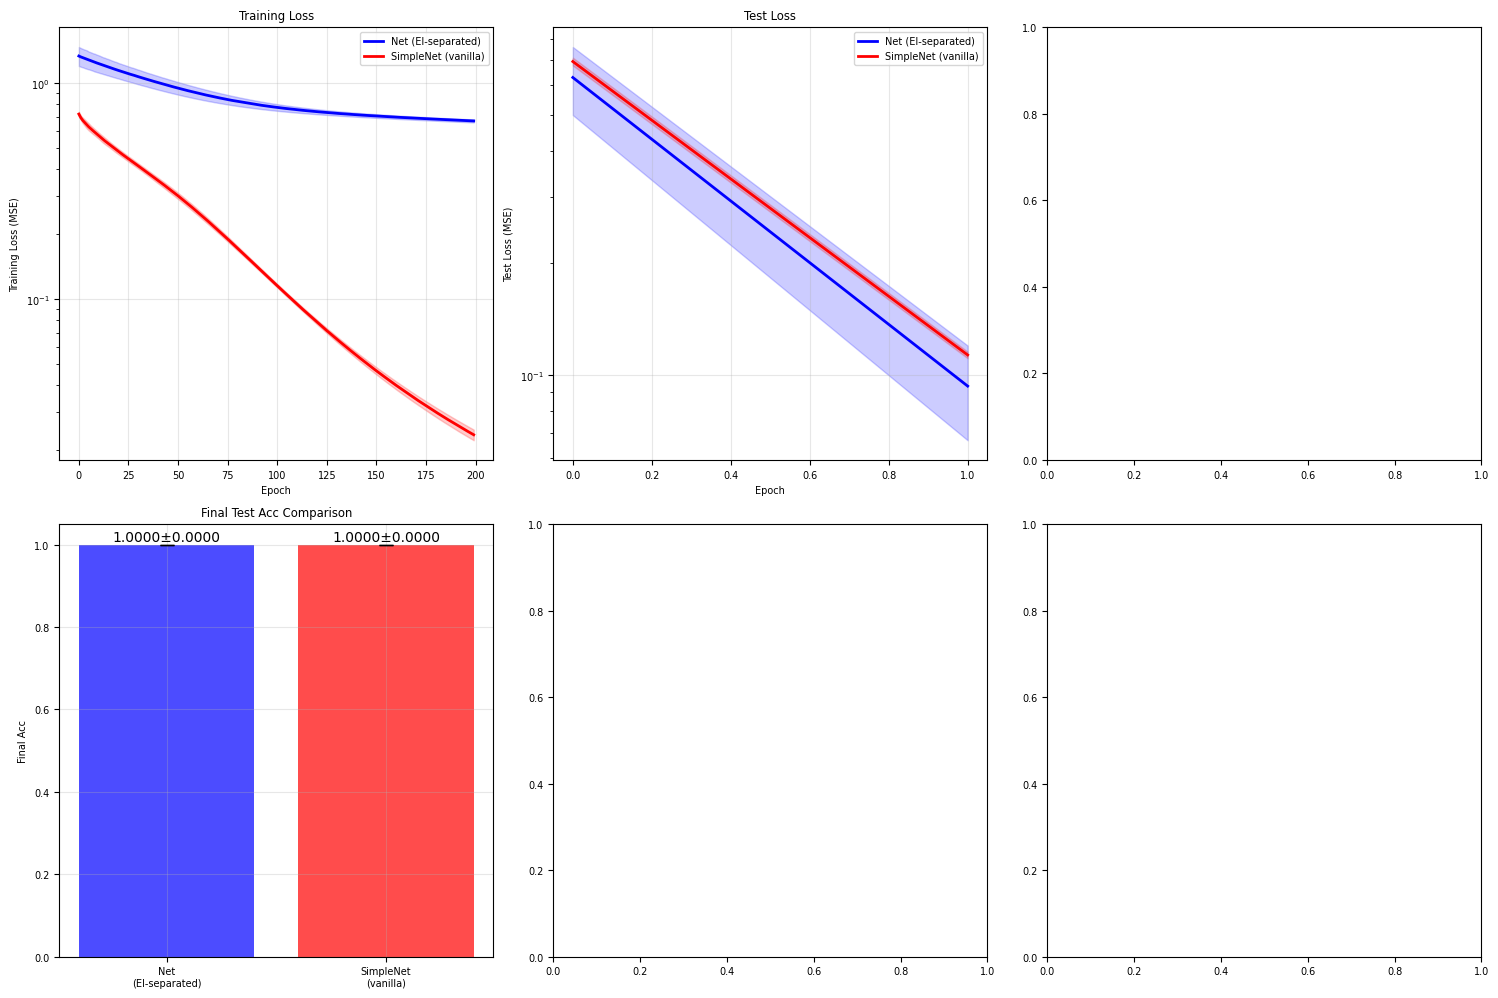

In [ ]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')

    # Final MSE comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

In [ ]:
print(1)

1


## 8. Test Predictions Visualization


In [ ]:
# # Train final models for prediction visualization
# torch.manual_seed(0)
# np.random.seed(0)

# # Train final models
# final_net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
# final_simple = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)

# print("Training final models for prediction visualization...")
# train_model(final_net, train_loader, test_loader, epochs=epochs)
# train_model(final_simple, train_loader, test_loader, epochs=epochs)

# # Get predictions
# _, _, _, net_predictions, net_targets = evaluate_model(final_net, test_loader)
# _, _, _, simple_predictions, simple_targets = evaluate_model(final_simple, test_loader)

# # Plot predictions vs targets
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# # Net predictions
# ax1.scatter(net_targets, net_predictions, alpha=0.6, color='blue')
# ax1.plot([0, 2], [0, 2], 'r--', linewidth=2, label='Perfect prediction')
# ax1.set_xlabel('True Values')
# ax1.set_ylabel('Predicted Values')
# ax1.set_title('Net (EI-separated RNN) Predictions')
# ax1.legend()
# ax1.grid(True, alpha=0.3)
# ax1.set_aspect('equal')

# # Calculate correlation
# net_corr = np.corrcoef(net_targets, net_predictions)[0, 1]
# ax1.text(0.05, 0.95, f'Correlation: {net_corr:.4f}',
#          transform=ax1.transAxes, verticalalignment='top',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# # SimpleNet predictions
# ax2.scatter(simple_targets, simple_predictions, alpha=0.6, color='red')
# ax2.plot([0, 2], [0, 2], 'r--', linewidth=2, label='Perfect prediction')
# ax2.set_xlabel('True Values')
# ax2.set_ylabel('Predicted Values')
# ax2.set_title('SimpleNet (vanilla RNN) Predictions')
# ax2.legend()
# ax2.grid(True, alpha=0.3)
# ax2.set_aspect('equal')

# # Calculate correlation
# simple_corr = np.corrcoef(simple_targets, simple_predictions)[0, 1]
# ax2.text(0.05, 0.95, f'Correlation: {simple_corr:.4f}',
#          transform=ax2.transAxes, verticalalignment='top',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# plt.tight_layout()
# plt.show()

# print(f"Net correlation: {net_corr:.4f}")
# print(f"SimpleNet correlation: {simple_corr:.4f}")